In [1]:
import pandas as pd
import numpy as np

In [2]:
Xtr = pd.read_csv('data/X_train.csv')
ytr = pd.read_csv('data/y_train.csv')
Xte = pd.read_csv('data/X_test.csv')
X = Xtr.drop(columns='id')
y = ytr['y'].to_numpy()

## 1. Data exploration — know the data before modeling

The data is loaded in the cell above (`X`, `y`, `Xte`). Before tuning any model, we profile the data so that every preprocessing decision in the pipeline below is justified by evidence, not habit:

1. **Structure & integrity** — shapes, dtypes, id alignment, train/test consistency
2. **Missing values** — how many, where, and whether missingness carries information about `y` (MNAR check)
3. **Target `y`** — distribution, skewness, normality → do we need a target transform?
4. **Outliers & scale anomalies** — robust z-scores (median/MAD), one-sided spikes, wildly different feature scales
5. **Signal vs. noise** — Spearman correlation of every feature with `y` + permutation p-values + Benjamini–Hochberg FDR, and mutual information for non-linear signal
6. **Redundancy & dimensionality** — correlation structure of the top features + PCA: how much of the 832-dim space is real signal
7. **Feature budget** — an honest CV sweep over `k` to decide how many features to keep




In [3]:
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata

pd.set_option('display.width', 160)

Xt = Xte.drop(columns='id')   # feature matrix of the test set (same columns as X)

print(f'X_train {X.shape}   y_train {y.shape}   X_test {Xt.shape}')
print(f'dtypes: {X.dtypes.value_counts().to_dict()}')
print(f'id aligned between X_train and y_train : {(Xtr["id"].to_numpy() == ytr["id"].to_numpy()).all()}')
print(f'X_test has the same columns as X_train   : {(X.columns == Xt.columns).all()}')
print(f'duplicated rows in X                     : {X.duplicated().sum()}')
print(f'memory usage                             : {X.memory_usage(deep=True).sum() / 1e6:.1f} MB')
print(f'constant features (train)                : {X.columns[X.nunique(dropna=True) <= 1].tolist()}')
print('\nPer-feature summary (first 6 features) — note the wildly different scales:')
print(X.describe().T.loc[X.columns[:6]].round(3))


X_train (1212, 832)   y_train (1212,)   X_test (776, 832)
dtypes: {dtype('float64'): 832}
id aligned between X_train and y_train : True
X_test has the same columns as X_train   : True
duplicated rows in X                     : 0
memory usage                             : 8.1 MB
constant features (train)                : ['x104', 'x129', 'x489', 'x530']

Per-feature summary (first 6 features) — note the wildly different scales:
     count        mean       std        min        25%         50%         75%         max
x0  1121.0   15220.403  2314.736   5636.624  13846.178   15048.468   16653.018   28273.690
x1  1128.0   10950.161  1570.611   6764.061   9859.438   10839.483   11902.079   17777.338
x2  1124.0    3430.837   443.431   1849.453   3152.193    3401.540    3698.565    5622.952
x3  1121.0  100002.281  9708.061  65828.916  93497.928  100053.800  106139.853  133145.632
x4  1138.0     105.070     2.835    100.057    102.679     105.030     107.517     110.087
x5  1133.0      99.969 

NaN entries: 76,902 / 1,008,384 (7.63%)
spread over 832 / 832 features and 1212 / 1212 rows
fully-NaN columns: []   |   test NaN: 6.29%


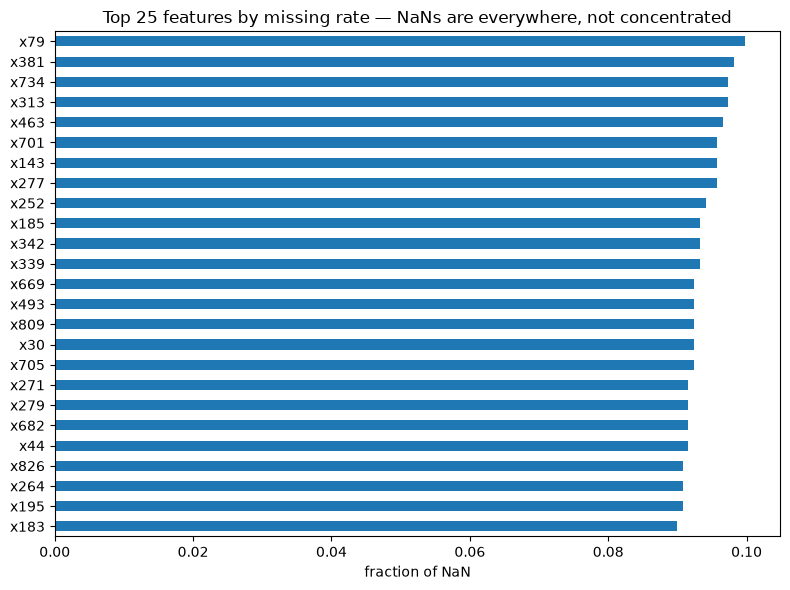


y by per-row NaN-count bucket (missingness ~unrelated to y -> impute, do not drop rows):
                 mean    std  count
bucket                             
(36.948, 43.5]  67.40   5.13      5
(43.5, 50.0]    68.61  11.65     59
(50.0, 56.5]    69.23  10.41    157
(56.5, 63.0]    69.83   9.08    392
(63.0, 69.5]    70.65   9.35    341
(69.5, 76.0]    69.01  10.51    202
(76.0, 82.5]    72.04   9.40     48
(82.5, 89.0]    73.62   7.03      8


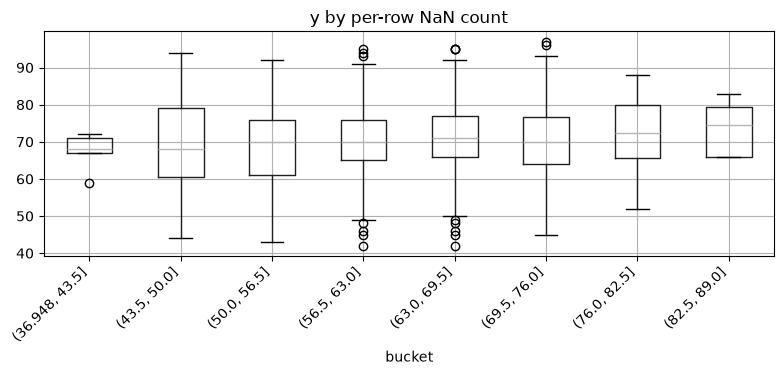

In [4]:
nan_frac = X.isna().mean()
nan_pct = X.isna().to_numpy().mean() * 100
print(f'NaN entries: {int(X.isna().to_numpy().sum()):,} / {X.size:,} ({nan_pct:.2f}%)')
print(f'spread over {(nan_frac > 0).sum()} / {X.shape[1]} features and {int(X.isna().any(axis=1).sum())} / {len(X)} rows')
print(f'fully-NaN columns: {X.columns[X.isna().all()].tolist()}   |   test NaN: {Xt.isna().to_numpy().mean() * 100:.2f}%')

top_nan = nan_frac.sort_values(ascending=False).head(25)
fig, ax = plt.subplots(figsize=(8, 6))
top_nan[::-1].plot.barh(ax=ax)
ax.set_xlabel('fraction of NaN')
ax.set_title('Top 25 features by missing rate — NaNs are everywhere, not concentrated')
plt.tight_layout(); plt.show()

# MNAR check: does the amount of missingness per row relate to y?
nan_per_row = X.isna().sum(axis=1)
mnar = pd.DataFrame({'nan_count': nan_per_row, 'y': y})
mnar['bucket'] = pd.cut(nan_per_row, bins=8)
print('\ny by per-row NaN-count bucket (missingness ~unrelated to y -> impute, do not drop rows):')
print(mnar.groupby('bucket', observed=True)['y'].agg(['mean', 'std', 'count']).round(2))
fig, ax = plt.subplots(figsize=(8, 4))
mnar.boxplot(column='y', by='bucket', ax=ax)
ax.set_title('y by per-row NaN count')
plt.suptitle('')
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()


count    1212.000
mean       69.889
std         9.721
min        42.000
25%        64.000
50%        70.000
75%        77.000
max        97.000

skew = -0.207   excess kurtosis = -0.104   normaltest p = 0.011


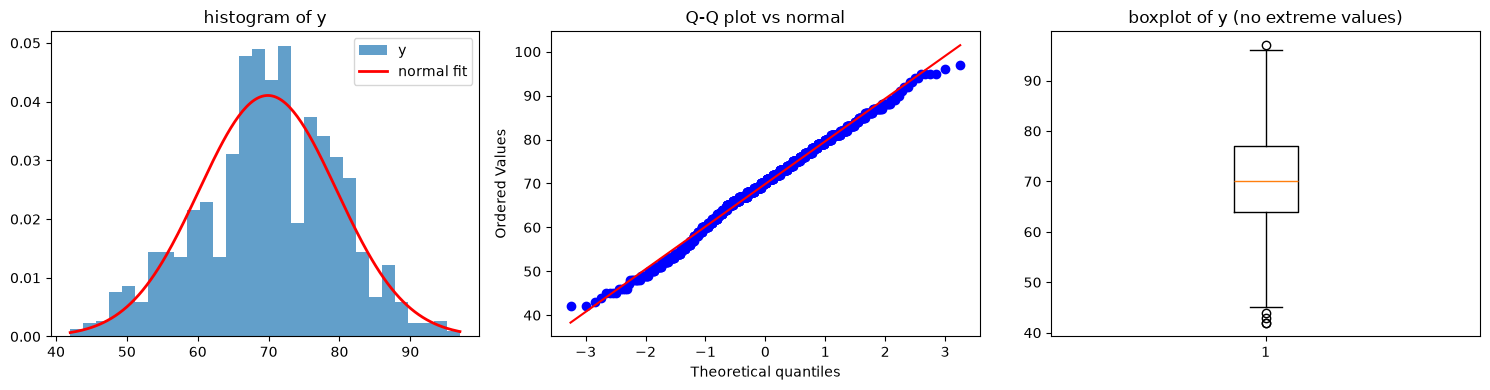


Decision: y is roughly symmetric (mild left skew), range 42-97, no extreme values
-> no target transform needed; the pipeline only standardizes y so SVR hyperparameters are meaningful.


In [5]:
y_skew = stats.skew(y)
print(pd.Series(y, name='y').describe().round(3).to_string())
print(f"\nskew = {y_skew:.3f}   excess kurtosis = {stats.kurtosis(y):.3f}   normaltest p = {stats.normaltest(y).pvalue:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(y, bins=30, density=True, alpha=0.7, label='y')
xs = np.linspace(y.min(), y.max(), 200)
axes[0].plot(xs, stats.norm.pdf(xs, y.mean(), y.std()), 'r-', lw=2, label='normal fit')
axes[0].set_title('histogram of y'); axes[0].legend()
stats.probplot(y, dist='norm', plot=axes[1]); axes[1].set_title('Q-Q plot vs normal')
axes[2].boxplot(y); axes[2].set_title('boxplot of y (no extreme values)')
plt.tight_layout(); plt.show()

print('\nDecision: y is roughly symmetric (mild left skew), range 42-97, no extreme values')
print('-> no target transform needed; the pipeline only standardizes y so SVR hyperparameters are meaningful.')


entries beyond 8 robust sigmas: 258 (0.026%)  — 254 high-side spikes vs 4 low-side
features with the most outliers:
 x742    120
x115     51
x143     32
x641     20
x507      8
x413      6
x415      4
x796      2
x665      2
x531      2

most extreme values (up to ~1e23!):
 x665    9.935455e+23
x173    2.937933e+23
x596    8.756492e+14
x342    5.032106e+06
x132    2.819624e+06
x554    2.356201e+06
x217    1.454985e+06
x740    1.448078e+06

features on a huge scale (median |x| > 1e6): 73 / 832 in train, 70 in test
-> a systematic rescaling of a feature block, present in train AND test


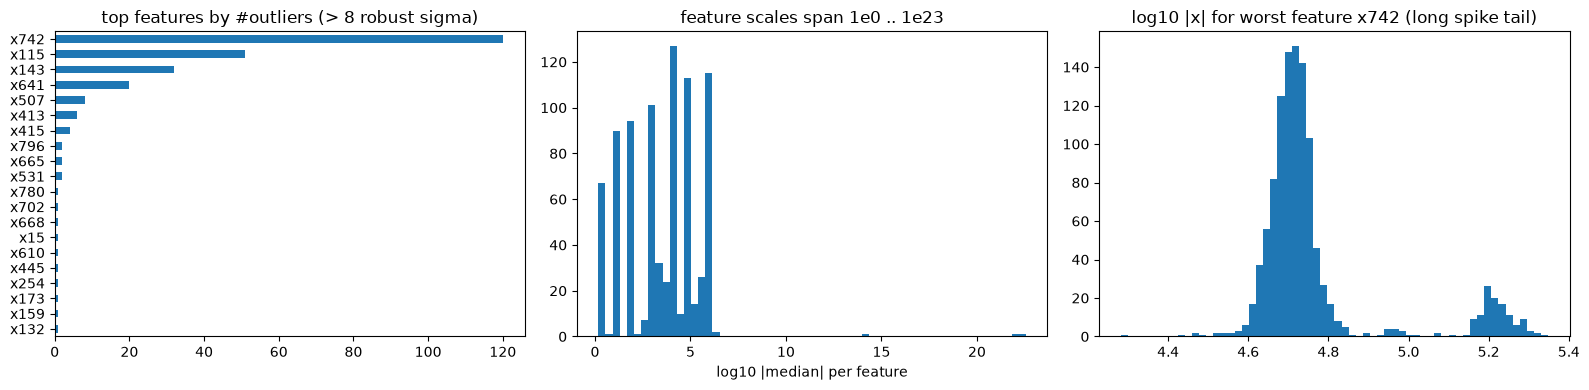


Decision: mask these entries to NaN (MADOutlierMasker, thresh=8) and impute them later;
median/MAD are robust, so the spikes do not distort the detection itself.


In [6]:
Xv = X.to_numpy(dtype=float)
med = np.nanmedian(Xv, axis=0)
mad = np.nanmedian(np.abs(Xv - med), axis=0)
q1, q3 = np.nanpercentile(Xv, [25, 75], axis=0)
scale = np.where(mad > 0, mad / 0.6745, (q3 - q1) / 1.349)   # robust sigma = MAD/0.6745, IQR fallback
scale = np.where(scale > 0, scale, np.inf)                     # zero-scale columns are never flagged
z = (Xv - med) / scale

n_out = pd.Series((np.abs(z) > 8).sum(axis=0), index=X.columns)
print(f'entries beyond 8 robust sigmas: {int((np.abs(z) > 8).sum())} ({(np.abs(z) > 8).mean() * 100:.3f}%)'
      f'  — {int((z > 8).sum())} high-side spikes vs {int((z < -8).sum())} low-side')
print('features with the most outliers:\n', n_out[n_out > 0].sort_values(ascending=False).head(10).to_string())

maxv = np.nanmax(np.abs(Xv), axis=0)
print('\nmost extreme values (up to ~1e23!):\n', pd.Series(maxv, index=X.columns).sort_values(ascending=False).head(8).to_string())

med_abs = np.abs(med)
n_big = int((med_abs > 1e6).sum())
n_big_test = int((np.abs(np.nanmedian(Xt.to_numpy(dtype=float), axis=0)) > 1e6).sum())
print(f'\nfeatures on a huge scale (median |x| > 1e6): {n_big} / {X.shape[1]} in train, {n_big_test} in test')
print('-> a systematic rescaling of a feature block, present in train AND test')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
n_out[n_out > 0].sort_values(ascending=False).head(20)[::-1].plot.barh(ax=axes[0])
axes[0].set_title('top features by #outliers (> 8 robust sigma)')
axes[1].hist(np.log10(med_abs[med_abs > 0]), bins=60)
axes[1].set_xlabel('log10 |median| per feature')
axes[1].set_title('feature scales span 1e0 .. 1e23')
worst = n_out.idxmax()
col = Xv[:, X.columns.get_loc(worst)]
axes[2].hist(np.log10(np.abs(col[~np.isnan(col)]) + 1e-12), bins=60)
axes[2].set_title(f'log10 |x| for worst feature {worst} (long spike tail)')
plt.tight_layout(); plt.show()

print('\nDecision: mask these entries to NaN (MADOutlierMasker, thresh=8) and impute them later;')
print('median/MAD are robust, so the spikes do not distort the detection itself.')


features with |Spearman rho| >= 0.1                          : 201
features significant after permutation test + BH FDR (q=0.05): 217   <- these carry the alpha

top 20 features by |rho| (with empirical p-value):
         rho  p_perm
x115  0.5500  0.0005
x415  0.5456  0.0005
x159  0.5287  0.0005
x458  0.5150  0.0005
x702  0.5106  0.0005
x507  0.5098  0.0005
x133 -0.5024  0.0005
x485 -0.5004  0.0005
x334 -0.4973  0.0005
x194 -0.4972  0.0005
x465 -0.4814  0.0005
x641  0.4500  0.0005
x200 -0.4302  0.0005
x287 -0.4201  0.0005
x712 -0.4187  0.0005
x654 -0.4124  0.0005
x362 -0.4112  0.0005
x531 -0.4065  0.0005
x410 -0.4000  0.0005
x306 -0.3996  0.0005


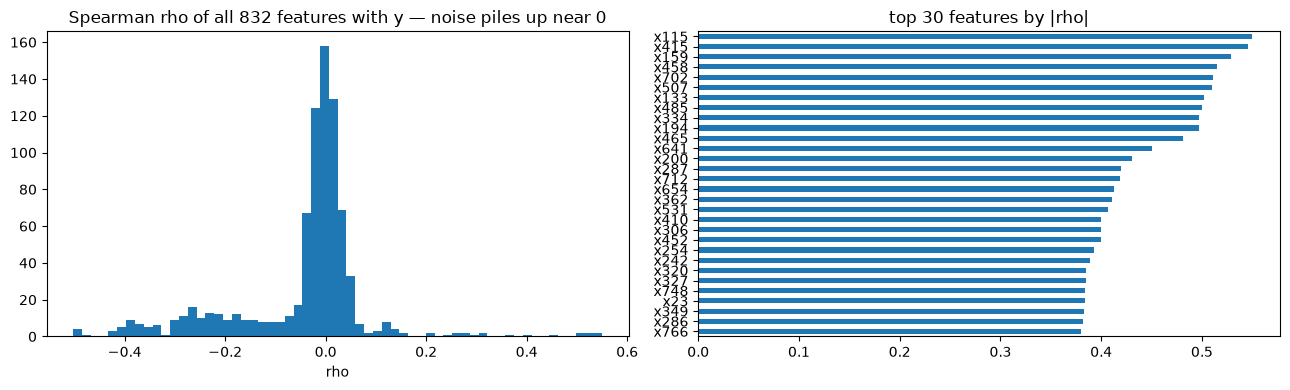

In [7]:
# Clean copy for univariate analysis: mask the 8-sigma outliers found above, then median-impute
Xi = Xv.copy()
Xi[np.abs(z) > 8] = np.nan
col_med = np.nanmedian(Xi, axis=0)
col_med = np.where(np.isnan(col_med), 0.0, col_med)
r, c = np.where(np.isnan(Xi))
Xi[r, c] = col_med[c]

# Spearman rho of every feature with y  (= Pearson on ranks: robust, catches monotonic non-linearity)
Xr = rankdata(Xi, axis=0)
xstd = Xr.std(0)
Xz = np.divide(Xr - Xr.mean(0), xstd, out=np.zeros_like(Xr), where=xstd > 0)  # constant cols -> 0
ry = rankdata(y)
yz = (ry - ry.mean()) / ry.std()
rho = pd.Series((Xz * yz[:, None]).mean(0), index=X.columns)
rho[xstd == 0] = np.nan   # constant features have no defined correlation

# Permutation test: shuffle y to get the null distribution of |rho| for each of the 832 features
rng = np.random.default_rng(42)
B = 2000
obs = np.abs(rho.to_numpy())
count = np.zeros(X.shape[1])
for _ in range(B):
    rp = (Xz * yz[rng.permutation(len(y))][:, None]).mean(0)
    count += (np.abs(rp) >= obs)
pval = (1 + count) / (B + 1)
pval[xstd == 0] = 1.0      # constant features: no evidence, excluded from FDR

# Benjamini-Hochberg FDR control at q = 0.05 across all 832 features (multiple-testing aware)
m = len(pval)
order = np.argsort(pval)
ok = pval[order] <= 0.05 * np.arange(1, m + 1) / m
kmax = np.max(np.where(ok)[0]) if ok.any() else -1
n_sig = kmax + 1 if kmax >= 0 else 0

print(f'features with |Spearman rho| >= 0.1                          : {int((rho.abs() >= 0.1).sum())}')
print(f'features significant after permutation test + BH FDR (q=0.05): {n_sig}   <- these carry the alpha')
print('\ntop 20 features by |rho| (with empirical p-value):')
print(pd.DataFrame({'rho': rho, 'p_perm': pval}).reindex(rho.abs().sort_values(ascending=False).index).head(20).round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(rho, bins=60)
axes[0].set_title('Spearman rho of all 832 features with y — noise piles up near 0')
axes[0].set_xlabel('rho')
rho.abs().sort_values(ascending=False).head(30)[::-1].plot.barh(ax=axes[1])
axes[1].set_title('top 30 features by |rho|')
plt.tight_layout(); plt.show()


top 15 features by mutual information (catches non-monotonic relationships too):
x115    0.1933
x133    0.1928
x458    0.1906
x507    0.1768
x702    0.1669
x159    0.1658
x334    0.1636
x415    0.1616
x485    0.1601
x465    0.1514
x410    0.1499
x194    0.1452
x146    0.1299
x242    0.1280
x641    0.1266

overlap between top-100 by |rho| and top-100 by MI: 73 / 100
-> the two independent rankings agree: the signal is real, not a monotonicity artifact


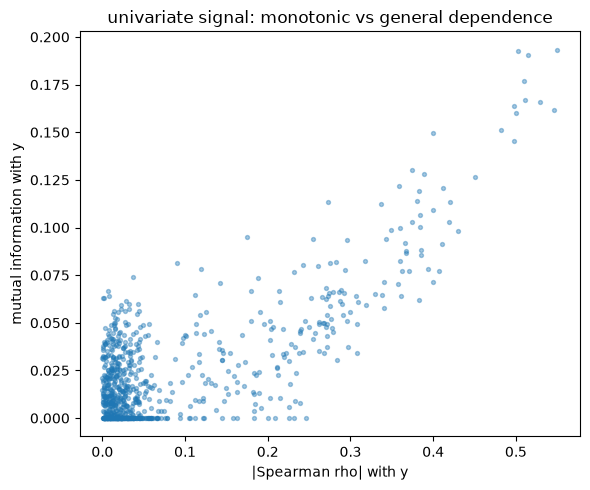

In [8]:
from sklearn.feature_selection import mutual_info_regression

mi = pd.Series(mutual_info_regression(Xi, y, random_state=0, n_jobs=-1), index=X.columns)
print('top 15 features by mutual information (catches non-monotonic relationships too):')
print(mi.sort_values(ascending=False).head(15).round(4).to_string())

top100_rho = set(rho.abs().sort_values(ascending=False).head(100).index)
top100_mi = set(mi.sort_values(ascending=False).head(100).index)
print(f'\noverlap between top-100 by |rho| and top-100 by MI: {len(top100_rho & top100_mi)} / 100')
print('-> the two independent rankings agree: the signal is real, not a monotonicity artifact')

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(rho.abs(), mi, s=8, alpha=0.4)
ax.set_xlabel('|Spearman rho| with y')
ax.set_ylabel('mutual information with y')
ax.set_title('univariate signal: monotonic vs general dependence')
plt.tight_layout(); plt.show()


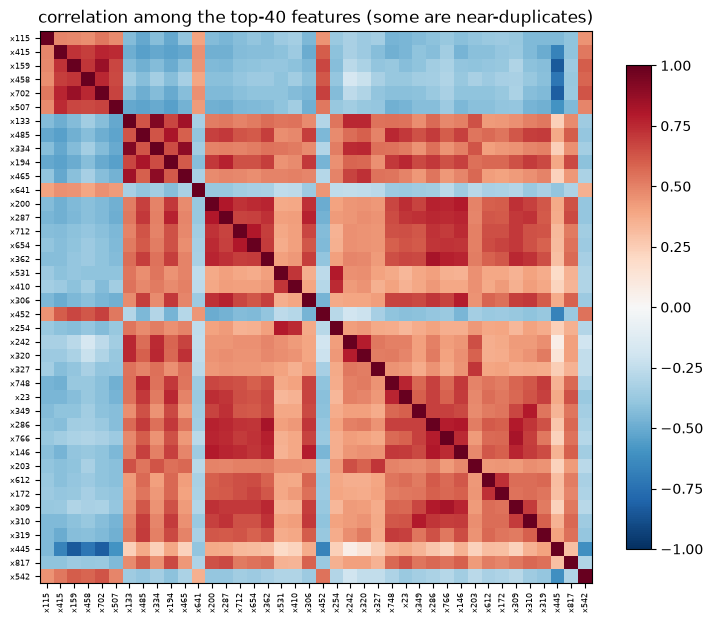

PCA on the 832 standardized features: 521 components explain 95% of the variance
(the variance is spread thinly over hundreds of directions -> mostly noise dimensions)

Spearman rho of PC1..PC10 with y: [-0.342 -0.388  0.375 -0.147  0.064 -0.022  0.012 -0.068 -0.051 -0.062]
-> only the first few PCs carry signal; the rest are noise directions


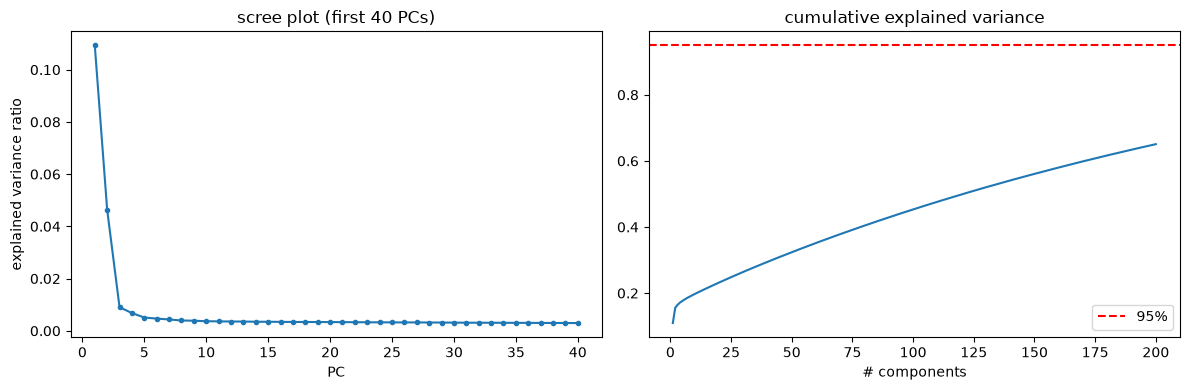

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

top40 = rho.abs().sort_values(ascending=False).head(40).index
corr = pd.DataFrame(Xi, columns=X.columns)[top40].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr.to_numpy(), vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(top40)), top40, rotation=90, fontsize=6)
ax.set_yticks(range(len(top40)), top40, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('correlation among the top-40 features (some are near-duplicates)')
plt.tight_layout(); plt.show()

Xs = StandardScaler().fit_transform(Xi)
pca = PCA(random_state=0).fit(Xs)
pcs = pca.transform(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f'PCA on the 832 standardized features: {n95} components explain 95% of the variance')
print('(the variance is spread thinly over hundreds of directions -> mostly noise dimensions)')

pc_rho = [stats.spearmanr(pcs[:, i], y).statistic for i in range(10)]
print('\nSpearman rho of PC1..PC10 with y:', np.round(pc_rho, 3))
print('-> only the first few PCs carry signal; the rest are noise directions')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, 41), pca.explained_variance_ratio_[:40], 'o-', ms=3)
axes[0].set_title('scree plot (first 40 PCs)'); axes[0].set_xlabel('PC'); axes[0].set_ylabel('explained variance ratio')
axes[1].plot(np.arange(1, 201), cum[:200])
axes[1].axhline(0.95, color='r', ls='--', label='95%')
axes[1].set_title('cumulative explained variance'); axes[1].set_xlabel('# components'); axes[1].legend()
plt.tight_layout(); plt.show()


k =  10: CV R2 = 0.3697 +/- 0.0591
k =  20: CV R2 = 0.3894 +/- 0.0722
k =  30: CV R2 = 0.3918 +/- 0.0728
k =  40: CV R2 = 0.3925 +/- 0.0765
k =  50: CV R2 = 0.4023 +/- 0.0843
k =  60: CV R2 = 0.4008 +/- 0.0841
k =  70: CV R2 = 0.4027 +/- 0.0849
k =  80: CV R2 = 0.4068 +/- 0.0846
k =  90: CV R2 = 0.4114 +/- 0.0871
k = 100: CV R2 = 0.4189 +/- 0.0859
k = 110: CV R2 = 0.4169 +/- 0.0903
k = 120: CV R2 = 0.4166 +/- 0.0941
k = 130: CV R2 = 0.4232 +/- 0.0981
k = 140: CV R2 = 0.4247 +/- 0.0982
k = 150: CV R2 = 0.4277 +/- 0.0972
k = 160: CV R2 = 0.4246 +/- 0.1013
k = 170: CV R2 = 0.4255 +/- 0.1035
k = 180: CV R2 = 0.4255 +/- 0.0973
k = 190: CV R2 = 0.4232 +/- 0.0982
k = 200: CV R2 = 0.4233 +/- 0.0944
k = 210: CV R2 = 0.4226 +/- 0.0900
k = 220: CV R2 = 0.4187 +/- 0.0922
k = 230: CV R2 = 0.4193 +/- 0.0947
k = 240: CV R2 = 0.4141 +/- 0.0888
k = 250: CV R2 = 0.4159 +/- 0.0854
k = 260: CV R2 = 0.4132 +/- 0.0880
k = 270: CV R2 = 0.4163 +/- 0.0903
k = 280: CV R2 = 0.4182 +/- 0.0902
k = 290: CV R2 = 0.4

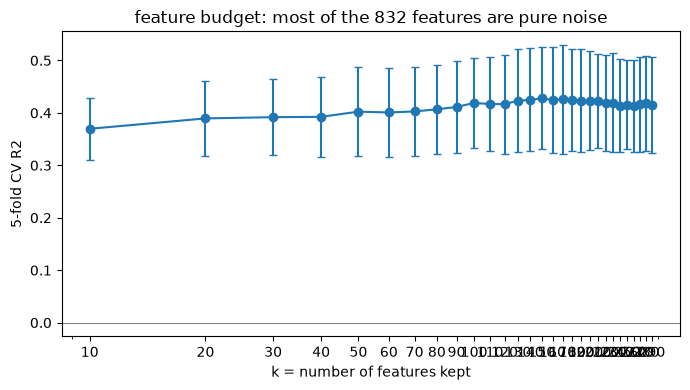

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_regression,mutual_info_regression
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_score
from functools import partial
from sklearn.ensemble import HistGradientBoostingRegressor

# Honest 5-fold CV: the whole preprocessing is refit inside each training fold (no leakage)

def k_pipe(k):
    alphas = np.logspace(-3, 3, 20)
    mi = partial(mutual_info_regression, random_state=42)
    return Pipeline([
        ('var', VarianceThreshold(0.0)),                        # drop the 4 constant features
        ('imp', SimpleImputer(strategy='median')),
        ('qt', QuantileTransformer(output_distribution='normal', n_quantiles=500, random_state=0)),
        ('sel', SelectKBest(mi, k=('all' if k >= X.shape[1] else k))),
        ('ridge', RidgeCV(alphas=alphas)),
    ])

ks = np.arange(10,300,10)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
sweep = {}
for k in ks:
    s = cross_val_score(k_pipe(k), X, y, cv=cv, scoring='r2', n_jobs=-1)
    sweep[k] = s
    print(f'k = {k:>3}: CV R2 = {s.mean():.4f} +/- {s.std():.4f}')
best_k = max(sweep, key=lambda k: sweep[k].mean())

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(ks, [sweep[k].mean() for k in ks], yerr=[sweep[k].std() for k in ks], marker='o', capsize=3)
ax.set_xscale('log'); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('k = number of features kept'); ax.set_ylabel('5-fold CV R2')
ax.set_title('feature budget: most of the 832 features are pure noise')
plt.tight_layout(); plt.show()


Using the 1-SE rule, we therefore select k=110 features because Any k whose mean is within 0.041 of the best (0.4319 − 0.041 = 0.391) is statistically indistinguishable from the best. In our data, everything from k≈110 up clears that bar. So we select the smallest one to have fewer features => less variance

In [11]:
import numpy as np
import pandas as pd
from functools import partial
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.feature_selection import SelectKBest, VarianceThreshold, mutual_info_regression
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split

# Deterministic MI
mi = partial(mutual_info_regression, random_state=0)

K = 110

pipe = Pipeline([
    ('var', VarianceThreshold(0.0)),
    ('imp', SimpleImputer(strategy='median')),
    ('qt',  QuantileTransformer(output_distribution='normal',
                                n_quantiles=500, random_state=0)),
    ('sel', SelectKBest(mi, k=K)),
    ('ridge', RidgeCV(alphas=np.logspace(-3, 3, 20))),
])

# --- Fit the final model on training data, evaluate honestly on the test set ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                   random_state=42)

pipe.fit(X_train, y_train)
print(f"Test R2: {pipe.score(X_test, y_test):.4f}")
print(f"Chosen alpha: {pipe['ridge'].alpha_:.3f}")

# --- Extract the selected 110 features ---
# Names of the features surviving preprocessing (variance threshold dropped
# the 4 constants, so this list has 828 entries, matching the 'sel' mask)
selected_features = pd.Index(pipe[:-1].get_feature_names_out())

# Selection mask, aligned with pre_names (828 == 828)
mask = pipe['sel'].get_support()
mi_scores = pd.Series(pipe['sel'].scores_[mask],
                      index=selected_features).sort_values(ascending=False)

print(mi_scores.head(15))
print(f"\n{len(selected_features)} features kept out of {X_train.shape[1]}")
selected_idx = np.where(mask)[0]              # positional indices in pre_names

# The 4 features dropped by VarianceThreshold (in original X space):
var_mask = pipe['var'].get_support()          # True = kept (832 entries)
dropped_features = X_train.columns[~var_mask]
print("Dropped by VarianceThreshold:", list(dropped_features))



# --- Save for later reuse ---
pd.Series(selected_features).to_csv("selected_features.csv", index=False)

Test R2: 0.4133
Chosen alpha: 233.572
x115    0.200535
x485    0.196450
x415    0.189812
x334    0.189722
x159    0.188859
x458    0.184412
x133    0.179354
x702    0.163687
x742    0.153600
x507    0.152177
x410    0.150242
x194    0.149054
x641    0.142466
x242    0.138738
x287    0.128465
dtype: float64

110 features kept out of 832
Dropped by VarianceThreshold: ['x104', 'x129', 'x489', 'x530']


## 2. Stacking regressor on the 110 selected features (Ridge + XGBoost + GP)

Each base learner gets the same preprocessing as `k_pipe` above (variance filter, median
imputation, quantile-to-normal), except the MI feature selection is replaced by the frozen
110-feature list `selected_features` from the previous cell (selecting fixed columns involves
no fitting, so it stays leak-free inside CV). `StackingRegressor` trains the meta-learner
(RidgeCV) on the out-of-fold predictions of the base learners, and the whole stack is scored
with an outer 5-fold CV so the evaluation itself is honest.

OOF R2 of each base model:
  ridge: R2 = 0.4100
    xgb: R2 = 0.5141
     gp: R2 = 0.4942

correlation of OOF predictions:
        ridge    xgb     gp
ridge  1.000  0.852  0.884
xgb    0.852  1.000  0.938
gp     0.884  0.938  1.000

correlation of OOF residuals (the one that matters for stacking):
        ridge    xgb     gp
ridge  1.000  0.870  0.896
xgb    0.870  1.000  0.933
gp     0.896  0.933  1.000


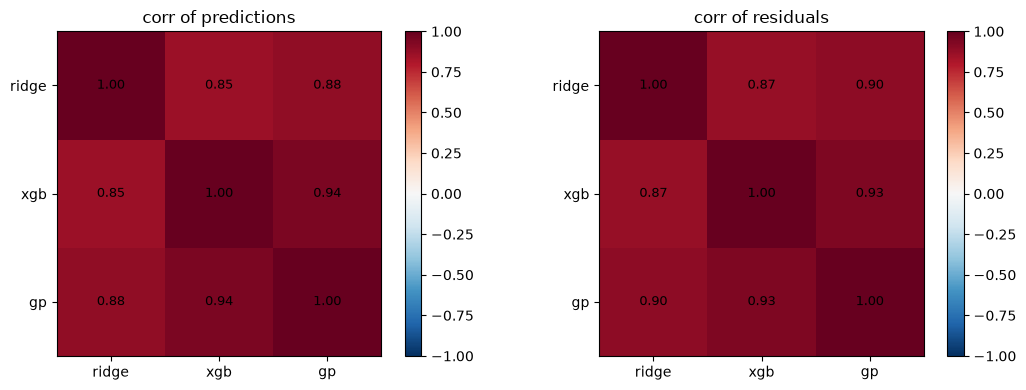

/opt/anaconda3/envs/amlproject1/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/envs/amlproject1/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


stack(Ridge+XGB+GP, k=110) CV R2 = 0.5145 +/- 0.0405


In [15]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import StackingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel, Matern
from xgboost import XGBRegressor 
# fallback if the selection cell above was not run in this session
if 'selected_features' not in globals():
    selected_features = pd.read_csv('selected_features.csv')['0']

class ColumnSelector(BaseEstimator, TransformerMixin):
    """Select fixed columns by name. Must be the first step, while X is still a DataFrame."""
    def __init__(self, cols): self.cols = cols
    def fit(self, X, y=None): return self
    def transform(self, X): return X[self.cols]

def pre_pipe():
    # identical to k_pipe, but the SelectKBest step is replaced by the frozen 110 columns.
    # var/imp/qt are all column-wise, so selecting columns first gives the same result.
    return Pipeline([
        ('sel', ColumnSelector(list(selected_features))),
        ('var', VarianceThreshold(0.0)),
        ('imp', SimpleImputer(strategy='median')),
        ('qt',  QuantileTransformer(output_distribution='normal', n_quantiles=500, random_state=0)),
    ])

alphas = np.logspace(-3, 3, 20)

ridge = Pipeline([('pre', pre_pipe()), ('model', RidgeCV(alphas=alphas))])

xgb = Pipeline([('pre', pre_pipe()), ('model', XGBRegressor(
    n_estimators=400, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=42, n_jobs=-1))])

gp = Pipeline([('pre', pre_pipe()), ('model', GaussianProcessRegressor(
    # features are ~N(0,1) after the quantile transform, so an isotropic RBF is a sane kernel
    kernel=ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(1),         
                     length_scale_bounds=(1e-2, 1e2), 
                     nu=2.5)
           + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-6, 1e1)),
    normalize_y=True, alpha=1e-8, n_restarts_optimizer=3, random_state=42))])

stack = StackingRegressor(
    estimators=[('ridge', ridge), ('xgb', xgb), ('gp', gp)],
    final_estimator=RidgeCV(alphas=alphas),   # meta-learner on the 3 out-of-fold predictions
    cv=KFold(5, shuffle=True, random_state=42),
    n_jobs=-1)

# --- diagnostic before fitting: which base model adds new alpha to the stack? ---
# Out-of-fold predictions per base model: if the *residuals* (errors) of two models are
# weakly correlated, they fail on different subjects and stacking can combine them.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score

cv = KFold(5, shuffle=True, random_state=42)
oof = pd.DataFrame({name: cross_val_predict(est, X, y, cv=cv, n_jobs=-1)
                    for name, est in stack.estimators})

print('OOF R2 of each base model:')
for name in oof.columns:
    print(f'  {name:>5}: R2 = {r2_score(y, oof[name]):.4f}')

corr_pred  = oof.corr()          # correlation of the predictions themselves
resid = pd.DataFrame(y[:, None] - oof.to_numpy(), columns=oof.columns, index=oof.index)
corr_resid = resid.corr()        # correlation of the errors: low => complementary models
print('\ncorrelation of OOF predictions:\n', corr_pred.round(3).to_string())
print('\ncorrelation of OOF residuals (the one that matters for stacking):\n',
      corr_resid.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, mat, title in [(axes[0], corr_pred, 'corr of predictions'),
                       (axes[1], corr_resid, 'corr of residuals')]:
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(len(mat)), mat.columns)
    ax.set_yticks(range(len(mat)), mat.index)
    for i in range(len(mat)):
        for j in range(len(mat)):
            ax.text(j, i, f'{mat.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

# honest evaluation: the whole stack (preprocessing included) is refit inside each outer fold
cv = KFold(5, shuffle=True, random_state=42)
s = cross_val_score(stack, X, y, cv=cv, scoring='r2', n_jobs=-1)
print(f'stack(Ridge+XGB+GP, k=110) CV R2 = {s.mean():.4f} +/- {s.std():.4f}')



In [ ]:
# fit on all training data and predict the test set
stack.fit(X, y)
y_pred = int(stack.predict(Xte.drop(columns='id')))
pd.DataFrame({'id': Xte['id'], 'y': y_pred}).to_csv('submission_stack.csv', index=False)